In [8]:
# ── CONFIG ────────────────────────────────────────────────────────────────────
# Model predictions — set to the modality you want to analyze (bm, pb, or fusion)
MODEL_PREDICTIONS_PATH_FUSION = "data/scemila_fusion_v15_predictions.csv"

# Clinical and survival data
# These exist for BM and PB separately. For FUSION predictions, use either —
# clinical/survival data is identical between modalities; only slide IDs differ.
CLINICAL_DATA_FILE = "data/eln/aml_mut_pred_unprocessed_clinical_data_bm_24-02-2026.csv"
SURVIVAL_DATA_FILE = "data/aml_mut_pred_survival_data_bm_24-02-2026.xlsx"
VAF_DATA_FILE      = "data/aml_mut_pred_vaf_values_bm_24-02-2026.xlsx"

# Change this to start a new run (prevents overwrites)
RUN_ID = "2026-04-30"

# Label for the clinical data used above ("bm" or "pb") — included in output filenames.
# For FUSION: set this to whichever clinical data table you chose above.
SLIDE_TYPE = "bm"

SELECTED_VARIABLES = [
    "CBFB-MYH11",
    "IDH2",
    "IDH_mutations",
    "KIT",
    "NPM1",
    "PML-RARA",
    "RTK_RAS_mutations",
    "STAG2",
    "TP53",
    "monosomy5_del_5q",
]
MODES = ["TARGETS", "TP", "FN", "TP_FP", "TP_FP_FN"]
VARIABLE_SETS = {
    "selected_variables": SELECTED_VARIABLES,
    "NPM1": ["NPM1"],
}

# Dummy data for local testing (no real patient files needed)
USE_DUMMY_DATA = False
if USE_DUMMY_DATA:
    CLINICAL_DATA_FILE = "data/dummy/clinical_data_bm.csv"
    SURVIVAL_DATA_FILE = "data/dummy/survival_data_bm.xlsx"
    VAF_DATA_FILE      = "data/dummy/vaf_values_bm.xlsx"
# ──────────────────────────────────────────────────────────────────────────────

In [9]:
import numpy as np
import pandas as pd
from pathlib import Path
from core.utils import load_predictions, add_confusion_categories


In [10]:
def get_data(model_results_path, clinical_data_path, survival_data_path, selected_variables):
    predicted_labels = load_predictions(model_results_path, selected_variables)
    predicted_labels = add_confusion_categories(predicted_labels, selected_variables)

    clinical_data = pd.read_csv(clinical_data_path)
    clinical_data.album_id = clinical_data.album_id.astype(str)
    predicted_labels.album_id = predicted_labels.album_id.astype(str)
    clinical_data = clinical_data.rename(columns={"year": "database_id"})

    df_merged = pd.merge(clinical_data, predicted_labels, on=["album_id", "database_id"], how="inner")

    df_survival = pd.read_excel(survival_data_path)
    eln_analysis_patients = df_survival[df_survival.cyto == True].henkilotunnus.to_list()
    df_merged = df_merged[df_merged.henkilotunnus.isin(eln_analysis_patients)]
    return df_merged


def add_confusion_categories(df, target_variables=None, keep_original=False):
    if target_variables is None:
        target_variables = [col[:-len("_true_label")] for col in df.columns if col.endswith("_true_label")]

    df = df.copy()
    for variable in target_variables:
        true_col = f"{variable}_true_label"
        pred_col = f"{variable}_pred_label"
        true = df[true_col]
        pred = df[pred_col]
        has_label = ~true.isna()
        category = pd.Series(index=df.index, dtype=object)
        category[has_label & (true == 1) & (pred == 1)] = "TP"
        category[has_label & (true == 0) & (pred == 0)] = "TN"
        category[has_label & (true == 0) & (pred == 1)] = "FP"
        category[has_label & (true == 1) & (pred == 0)] = "FN"
        df[f"{variable}_predicted"] = category

    if not keep_original:
        drop_cols = [
            col for variable in target_variables
            for col in (f"{variable}_true_label", f"{variable}_pred_label", f"{variable}_pred_prob")
            if col in df.columns
        ]
        df = df.drop(columns=drop_cols)

    return df

In [11]:
def replace_target_labels_with_predicted(df, columns, mode):
    stats = []
    any_changed_mask = pd.Series(False, index=df.index)

    for col in columns:
        pred_col = f"{col}_predicted"
        original = df[col]
        predicted = df[pred_col]

        unique_vals = original.dropna().unique()
        if set(unique_vals).issubset({"POS", "NEG"}):
            POS_VALUE, NEG_VALUE = "POS", "NEG"
        elif set(unique_vals).issubset({0, 1}):
            POS_VALUE, NEG_VALUE = 1, 0
        else:
            raise ValueError(f"Column {col} contains unsupported values: {unique_vals}")

        result = original.copy()

        if mode == "TARGETS":
            df = df.drop(columns=pred_col)
            continue

        if mode == "FN":
            result = result.mask((original == POS_VALUE) & (predicted == "TP"), NEG_VALUE)
        else:
            result = result.mask((original == POS_VALUE) & (predicted != "TP"), NEG_VALUE)

        if mode in ("TP_FP", "TP_FP_FN"):
            result = result.mask((original == NEG_VALUE) & (predicted == "FP"), POS_VALUE)

        if mode == "TP_FP_FN":
            result = result.mask((original == POS_VALUE) & (predicted == "FN"), NEG_VALUE)

        df[col] = result
        df = df.drop(columns=pred_col)

        changed_mask = (original != result) & ~(original.isna() & result.isna())
        any_changed_mask |= changed_mask

        stats.append({
            "mutation": col,
            "POS_to_NEG": ((original == POS_VALUE) & (result == NEG_VALUE)).sum(),
            "NEG_to_POS": ((original == NEG_VALUE) & (result == POS_VALUE)).sum(),
            "total_POS_before": (original == POS_VALUE).sum(),
            "total_NEG_before": (original == NEG_VALUE).sum(),
            "total_POS_after": (result == POS_VALUE).sum(),
            "total_NEG_after": (result == NEG_VALUE).sum(),
        })

    return df, pd.DataFrame(stats), df.loc[any_changed_mask, "henkilotunnus"].to_list()


def modify_target_labels_for_eln_stratification(df_input, r_input_dir, slide_type, run_id, experiments, variables, display_stats=False):
    modification_stats, modified_patients = {}, {}
    for variable_set_name, variable_set in variables.items():
        modification_stats[variable_set_name] = {}
        modified_patients[variable_set_name] = {}
        for experiment in experiments:
            df, stats, patients = replace_target_labels_with_predicted(df_input.copy(), columns=variable_set, mode=experiment)
            filename = f"aml_mut_pred_{experiment}_{variable_set_name}_clinical_data_{slide_type}_{run_id}.csv"
            df.to_csv(Path(r_input_dir) / filename, index=False)
            modification_stats[variable_set_name][experiment] = stats
            modified_patients[variable_set_name][experiment] = patients
            if display_stats:
                print(f"{variable_set_name} / {experiment}")
                display(stats)
    return modification_stats, modified_patients

In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import PathPatch
from matplotlib.path import Path as MplPath
from core.visualization.kaplan_meier import plot_kaplan_meier_curves


def plot_patient_flow_sankey(
    df1,
    df2,
    id_col="henkilotunnus",
    group_col="ELN1",
    categories=("Favorable", "Intermediate", "Adverse"),
    color_map={
        "Favorable": "tab:blue",
        "Intermediate": "tab:orange",
        "Adverse": "tab:red",
    },
    normalize=False,
    title="Patient Flow Between Risk Groups",
    df_labels=("Starting point", "End point"),
    plot_width=5,
    plot_height=3,
    fontsize=7,
    node_width=0.03,
    pad=0.06,
    save_path=None,
):
    df = df1[[id_col, group_col]].merge(df2[[id_col, group_col]], on=id_col, suffixes=("_t1", "_t2"))

    modified_patients = df[df[f"{group_col}_t1"] != df[f"{group_col}_t2"]]
    print(f"Num modified patients: {len(modified_patients)}")
    display(modified_patients)

    total = len(df)
    t1_counts = {c: (df[f"{group_col}_t1"] == c).sum() for c in categories}
    t2_counts = {c: (df[f"{group_col}_t2"] == c).sum() for c in categories}
    flow_counts = {
        (s, t): ((df[f"{group_col}_t1"] == s) & (df[f"{group_col}_t2"] == t)).sum()
        for s in categories for t in categories
    }

    color_map = {"Favorable": "tab:blue", "Intermediate": "tab:orange", "Adverse": "tab:red"}

    n = len(categories)
    available = 1.0 - (n - 1) * pad

    def _node_positions(counts):
        y_top, y_bot = {}, {}
        cursor = 1.0
        for c in categories:
            h = (counts[c] / total) * available
            y_top[c] = cursor
            y_bot[c] = cursor - h
            cursor = y_bot[c] - pad
        return y_top, y_bot

    t1_y_top, t1_y_bot = _node_positions(t1_counts)
    t2_y_top, t2_y_bot = _node_positions(t2_counts)

    src_y_top, src_y_bot = {}, {}
    for s in categories:
        cursor = t1_y_top[s]
        for t in categories:
            cnt = flow_counts[(s, t)]
            if cnt > 0:
                h = (cnt / total) * available
                src_y_top[(s, t)] = cursor
                src_y_bot[(s, t)] = cursor - h
                cursor -= h

    tgt_y_top, tgt_y_bot = {}, {}
    for t in categories:
        cursor = t2_y_top[t]
        for s in categories:
            cnt = flow_counts[(s, t)]
            if cnt > 0:
                h = (cnt / total) * available
                tgt_y_top[(s, t)] = cursor
                tgt_y_bot[(s, t)] = cursor - h
                cursor -= h

    fig, ax = plt.subplots(figsize=(plot_width, plot_height))
    x0 = node_width
    x1 = 1.0 - node_width

    y_data_range = 1.04
    min_dy = (fontsize / 72) / (plot_height / y_data_range) * 1.3
    flow_labels = []

    for s in categories:
        for t in categories:
            cnt = flow_counts[(s, t)]
            if cnt == 0:
                continue
            syb, syt = src_y_bot[(s, t)], src_y_top[(s, t)]
            tyb, tyt = tgt_y_bot[(s, t)], tgt_y_top[(s, t)]
            verts = [
                (x0, syb), (0.5, syb), (0.5, tyb), (x1, tyb),
                (x1, tyt), (0.5, tyt), (0.5, syt), (x0, syt), (x0, syb),
            ]
            codes = [
                MplPath.MOVETO, MplPath.CURVE4, MplPath.CURVE4, MplPath.CURVE4,
                MplPath.LINETO, MplPath.CURVE4, MplPath.CURVE4, MplPath.CURVE4, MplPath.CLOSEPOLY,
            ]
            ax.add_patch(PathPatch(MplPath(verts, codes), facecolor=color_map.get(s, "#aaaaaa"), edgecolor="none", alpha=0.4))
            if s != t:
                y_mid = 0.25 * (syb + syt + tyb + tyt)
                label = f"{cnt / total:.1%}" if normalize else str(int(cnt))
                flow_labels.append([y_mid, label])

    flow_labels.sort(key=lambda x: -x[0])
    for i in range(1, len(flow_labels)):
        if flow_labels[i - 1][0] - flow_labels[i][0] < min_dy:
            flow_labels[i][0] = flow_labels[i - 1][0] - min_dy

    for y_adj, label in flow_labels:
        ax.text(0.5, y_adj, label, ha="center", va="center", fontsize=fontsize - 1, color="black")

    for c in categories:
        color = color_map.get(c, "#aaaaaa")
        ax.fill_betweenx([t1_y_bot[c], t1_y_top[c]], 0, node_width, color=color)
        ax.fill_betweenx([t2_y_bot[c], t2_y_top[c]], 1.0 - node_width, 1.0, color=color)
        ax.text(-0.01, (t1_y_top[c] + t1_y_bot[c]) / 2, f"{c}\nN = {t1_counts[c]}", ha="right", va="center", fontsize=fontsize - 1)
        ax.text(1.01, (t2_y_top[c] + t2_y_bot[c]) / 2, f"{c}\nN = {t2_counts[c]}", ha="left", va="center", fontsize=fontsize - 1)

    ax.text(node_width / 2, 1.04, df_labels[0], ha="center", va="bottom", fontsize=fontsize - 1, fontweight="bold")
    ax.text(1.0 - node_width / 2, 1.04, df_labels[1], ha="center", va="bottom", fontsize=fontsize - 1, fontweight="bold")
    ax.set_xlim(-0.35, 1.35)
    ax.set_ylim(-0.02, 1.15)
    ax.axis("off")
    if title:
        ax.set_title(title, fontsize=fontsize)
    if save_path:
        plt.savefig(save_path, format="png", dpi=300, bbox_inches="tight")
    plt.show()
    return modified_patients


def get_data_for_sankey(df_survival, experiment, variable_set, slide_type, r_output_dir, run_id):
    filename = f"aml_mut_pred_{experiment}_{variable_set}_eln_{slide_type}_{run_id}.csv"
    df = pd.read_csv(Path(r_output_dir) / filename)
    df = pd.merge(df_survival, df, on=["album_id", "database_id", "henkilotunnus"], how="inner")
    df = df.dropna(subset="ELN1")
    df = pd.concat([df, pd.get_dummies(df["ELN1"], prefix="ELN1").astype(bool)], axis=1)
    return df


ELN_RISK_MAP = {"Favorable": 0, "Intermediate": 1, "Adverse": 2}


def concordance_index(event_times, predicted_scores, event_observed):
    t = np.asarray(event_times, dtype=float)
    s = np.asarray(predicted_scores, dtype=float)
    e = np.asarray(event_observed, dtype=bool)
    t_i, t_j = t[:, None], t[None, :]
    s_i, s_j = s[:, None], s[None, :]
    e_i = e[:, None]
    admissible = e_i & (t_i < t_j)
    concordant = np.sum(admissible & (s_i > s_j))
    discordant = np.sum(admissible & (s_i < s_j))
    tied_risk  = np.sum(admissible & (s_i == s_j))
    n_usable = concordant + discordant + tied_risk
    if n_usable == 0:
        return float("nan")
    return float(concordant + 0.5 * tied_risk) / n_usable


def execute_eln_kaplan_meier_experiments(experiments, df_survival, variable_set, slide_type, r_output_dir, run_id):
    for experiment in experiments:
        filename = f"aml_mut_pred_{experiment}_{variable_set}_eln_{slide_type}_{run_id}.csv"
        df = pd.read_csv(Path(r_output_dir) / filename)
        df = pd.merge(df_survival, df, on=["album_id", "database_id", "henkilotunnus"], how="inner")
        df = df.dropna(subset="ELN1")
        df = pd.concat([df, pd.get_dummies(df["ELN1"], prefix="ELN1").astype(bool)], axis=1)

        assert len(df[df.cyto == False]) == 0

        max_time = df["time_dg_to_death"].max()
        df["time_dg_to_death"] = df["time_dg_to_death"].fillna(max_time) / 30

        risk_cols = df.filter(like="ELN1_").columns.to_list()
        colors = {"ELN1_Favorable": "tab:blue", "ELN1_Intermediate": "tab:orange", "ELN1_Adverse": "tab:red"}
        plot_kaplan_meier_curves(
            df=df, time_col="time_dg_to_death", event_col="died", group_cols=risk_cols,
            colors=colors, title=f"Overall Survival by Risk Group ({experiment})",
            xlim=(0, 96), figsize=(6, 4), fontsize=14, xlabel="Time (months)",
            save_path=f"{variable_set}_Overall Survival by Risk Group ({experiment}).jpg".replace(" ", "_").replace("(", "_").replace(")", "_"),
        )

        risk_scores = df["ELN1"].map(ELN_RISK_MAP)
        valid = ~risk_scores.isna()
        c_idx = concordance_index(df.loc[valid, "time_dg_to_death"], risk_scores[valid], df.loc[valid, "died"])
        print(f"C-index ({experiment}): {c_idx:.3f}\n")

In [13]:
R_INPUT_DIR  = Path(f"/home/HUSTIETOALLAS/ext11670944/mounts/research/husdatalake/disease/scripts/AML_mutation_prediction/aml-mutation-prediction/data/eln/runs/{RUN_ID}/r_input")
R_OUTPUT_DIR = Path(f"/home/HUSTIETOALLAS/ext11670944/mounts/research/husdatalake/disease/scripts/AML_mutation_prediction/aml-mutation-prediction/data/eln/runs/{RUN_ID}/r_output")

if R_INPUT_DIR.exists() and any(R_INPUT_DIR.iterdir()):
    raise RuntimeError(
        f"Run '{RUN_ID}' already has files in r_input. "
        "Change RUN_ID in the config cell to start a new run."
    )

R_INPUT_DIR.mkdir(parents=True, exist_ok=True)
R_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

r_config = Path("data/eln/eln_run_config.R")
r_config.write_text(
    f'INPUT_DATA_DIR  <- "{R_INPUT_DIR}"\n'
    f'OUTPUT_DATA_DIR <- "{R_OUTPUT_DIR}"\n'
)
print(f"Run dirs created:\n  {R_INPUT_DIR}\n  {R_OUTPUT_DIR}")
print(f"R config written to: {r_config}")

RuntimeError: Run '2026-04-30' already has files in r_input. Change RUN_ID in the config cell to start a new run.

In [14]:
df_fusion = get_data(MODEL_PREDICTIONS_PATH_FUSION, CLINICAL_DATA_FILE, SURVIVAL_DATA_FILE, SELECTED_VARIABLES)
stats_fusion, modified_patients_fusion = modify_target_labels_for_eln_stratification(
    df_fusion, R_INPUT_DIR, SLIDE_TYPE, RUN_ID, MODES, VARIABLE_SETS
)

### Next step: Run the R script

```bash
Rscript 4_generate_eln_groups.R
```

Then continue with the analysis cells below.

In [15]:
df_survival = pd.read_excel(SURVIVAL_DATA_FILE)


Variable set: selected_variables


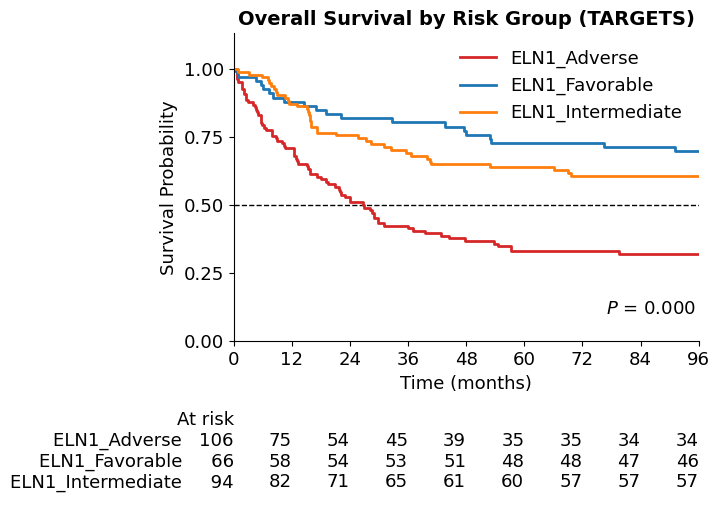

C-index (TARGETS): 0.635



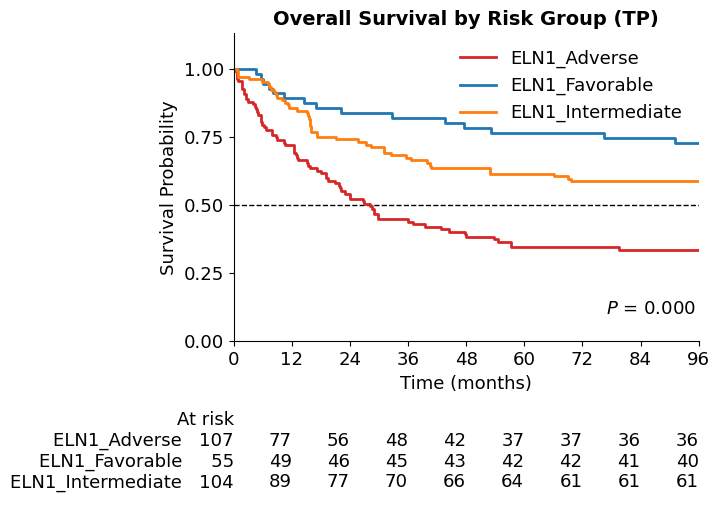

C-index (TP): 0.630



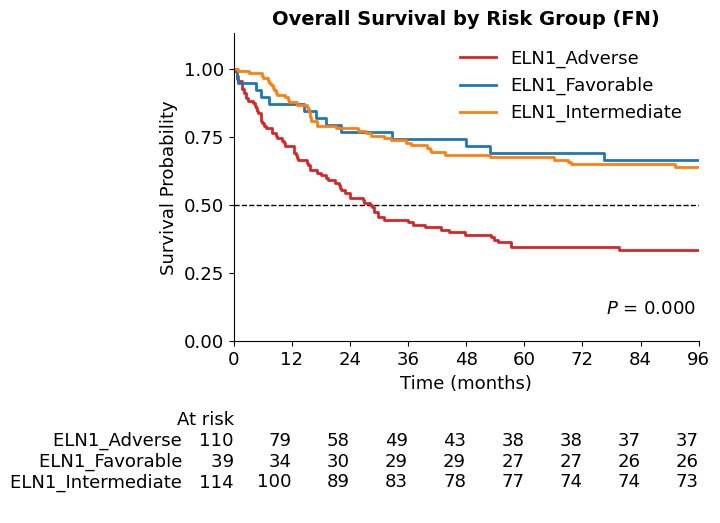

C-index (FN): 0.620



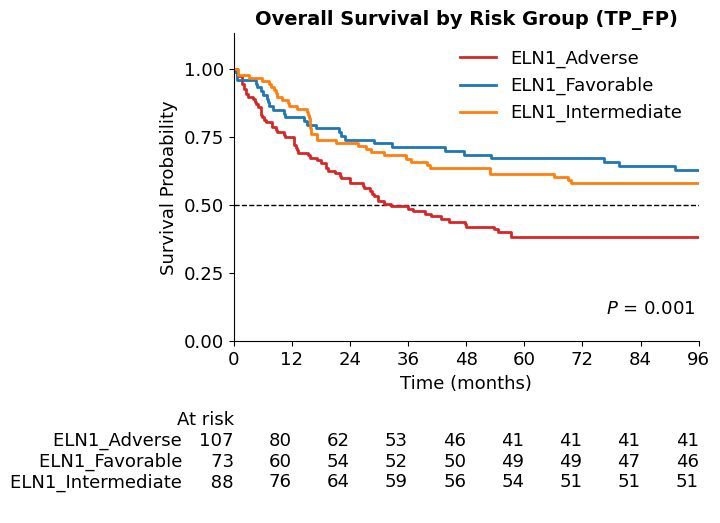

C-index (TP_FP): 0.585



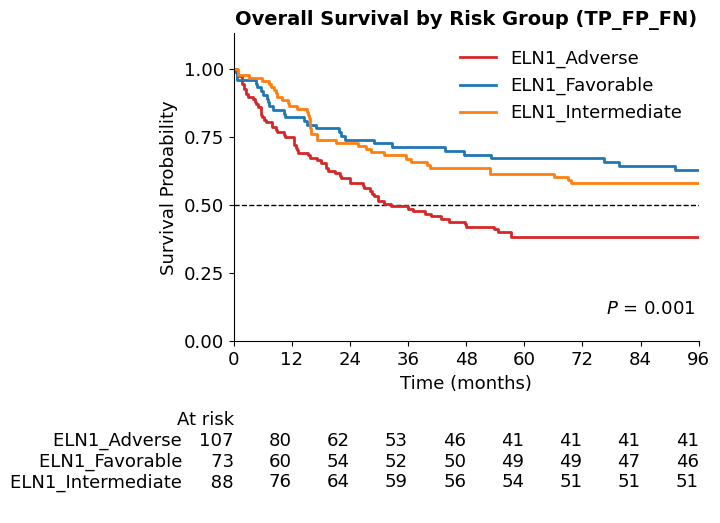

C-index (TP_FP_FN): 0.585


Variable set: NPM1


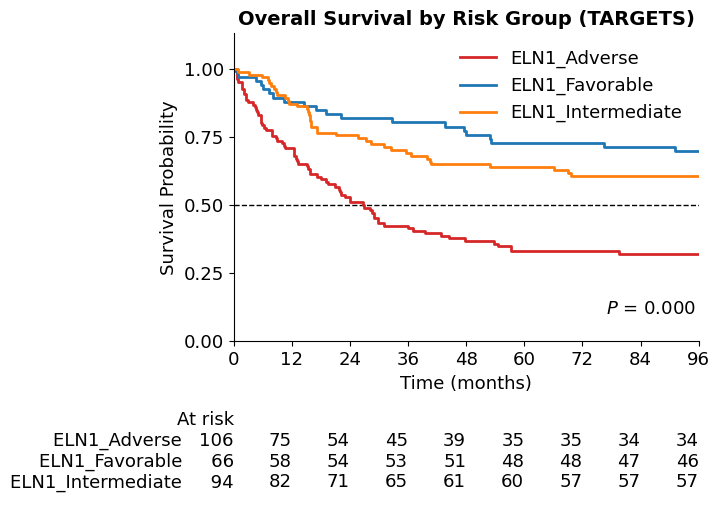

C-index (TARGETS): 0.635



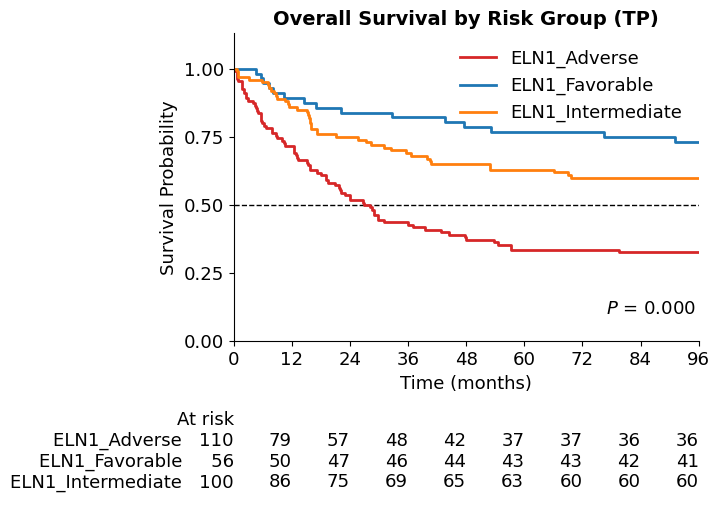

C-index (TP): 0.636



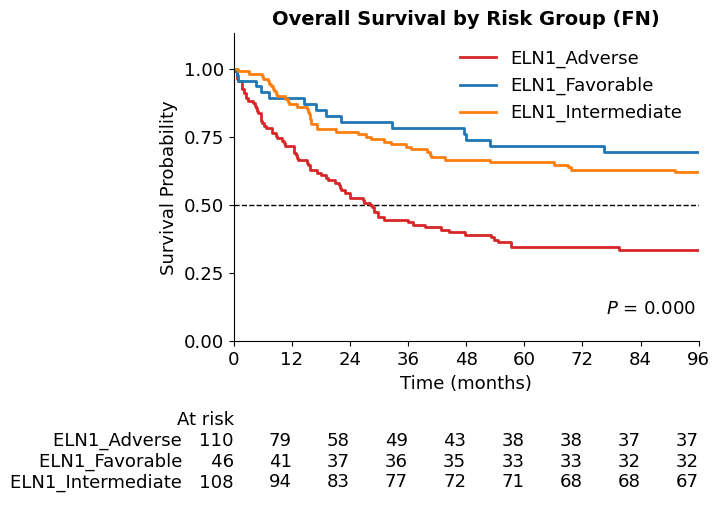

C-index (FN): 0.625



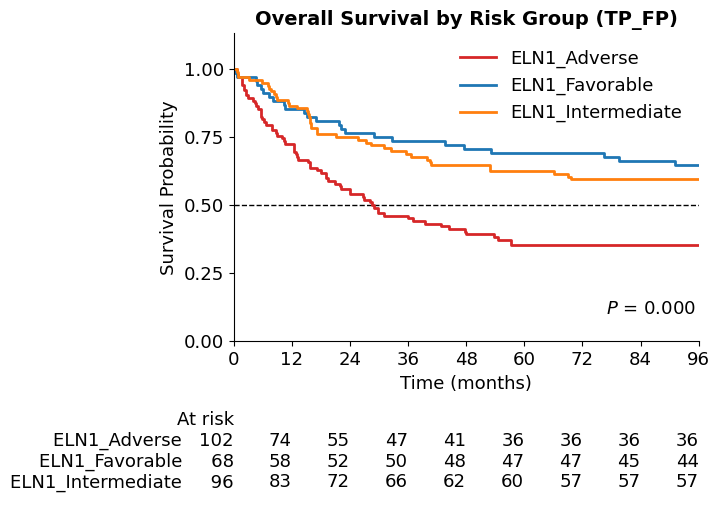

C-index (TP_FP): 0.605



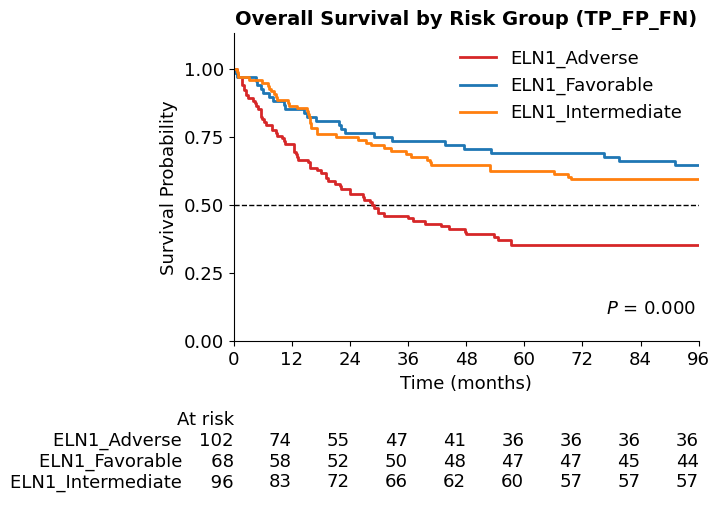

C-index (TP_FP_FN): 0.605



In [26]:
# All patients, all variable sets
for variable_set_name in VARIABLE_SETS:
    print(f"\n{'='*60}\nVariable set: {variable_set_name}\n{'='*60}")
    execute_eln_kaplan_meier_experiments(MODES, df_survival, variable_set_name, SLIDE_TYPE, R_OUTPUT_DIR, RUN_ID)

if False:
    # NPM1 subgroup: patients whose NPM1 classification changed under TP mode
    npm1_modified = modified_patients_fusion["NPM1"]["TP"]
    df_survival_npm1 = df_survival[df_survival.henkilotunnus.isin(npm1_modified)]
    print(f"\n{'='*60}\nNPM1 subgroup ({len(df_survival_npm1)} patients with modified labels)\n{'='*60}")
    execute_eln_kaplan_meier_experiments(["TARGETS", "TP"], df_survival_npm1, "NPM1", SLIDE_TYPE, R_OUTPUT_DIR, RUN_ID)

Num modified patients: 14


,henkilotunnus,ELN1_t1,ELN1_t2
18,02139_09308667,Favorable,Intermediate
31,02139_13916700,Favorable,Intermediate
33,02139_14390834,Favorable,Intermediate
88,02139_29811415,Adverse,Intermediate
90,02139_30873398,Favorable,Intermediate
93,02139_32599508,Adverse,Intermediate
114,02139_38340735,Adverse,Intermediate
129,02139_45032200,Favorable,Adverse
145,02139_52031677,Favorable,Intermediate
149,02139_52348920,Favorable,Adverse


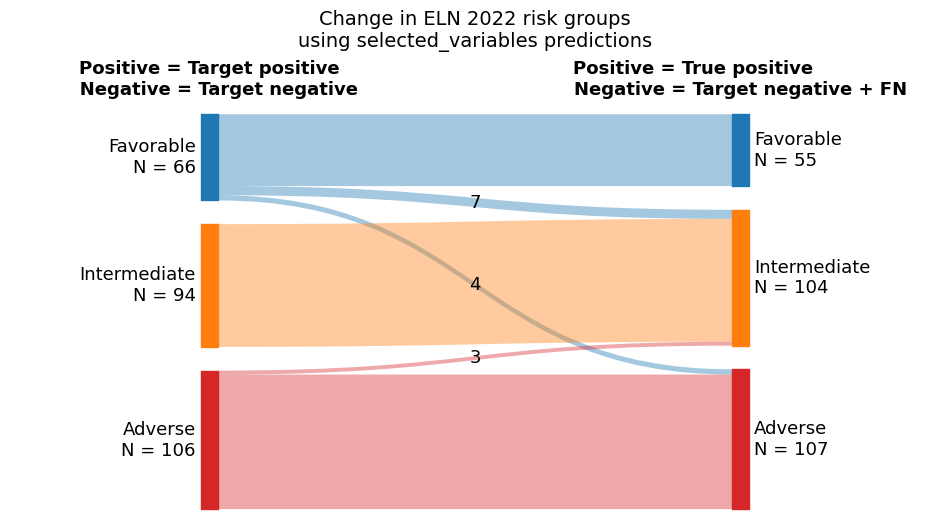

Num modified patients: 10


,henkilotunnus,ELN1_t1,ELN1_t2
18,02139_09308667,Favorable,Intermediate
31,02139_13916700,Favorable,Intermediate
33,02139_14390834,Favorable,Intermediate
90,02139_30873398,Favorable,Intermediate
129,02139_45032200,Favorable,Adverse
145,02139_52031677,Favorable,Intermediate
149,02139_52348920,Favorable,Adverse
163,02139_56745071,Favorable,Adverse
183,02139_63368117,Favorable,Adverse
264,02139_99568221,Favorable,Intermediate


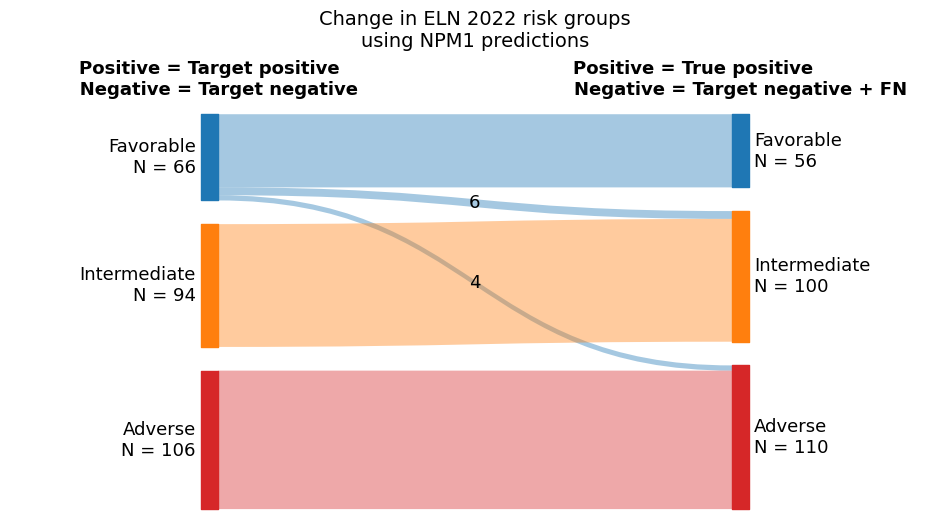

In [18]:
sankey_results = {}
for variable_set_name in VARIABLE_SETS:
    df1 = get_data_for_sankey(df_survival, "TARGETS", variable_set_name, SLIDE_TYPE, R_OUTPUT_DIR, RUN_ID)
    df2 = get_data_for_sankey(df_survival, "TP", variable_set_name, SLIDE_TYPE, R_OUTPUT_DIR, RUN_ID)
    mp = plot_patient_flow_sankey(
        df1, df2,
        title=f"Change in ELN 2022 risk groups\nusing {variable_set_name} predictions",
        df_labels=(
            "Positive = Target positive\n   Negative = Target negative",
            "Positive = True positive               \nNegative = Target negative + FN",
        ),
        plot_width=12,
        plot_height=6,
        fontsize=14,
    )
    sankey_results[variable_set_name] = mp

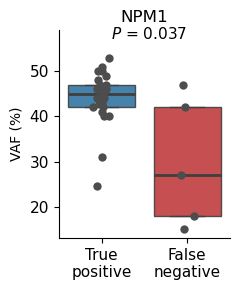

In [27]:
from core.visualization.box_plot import plot_covariate_distributions

patients = sankey_results["NPM1"].henkilotunnus.to_list()

df_vaf = pd.read_excel(VAF_DATA_FILE)
df_vaf = df_vaf[["henkilotunnus", "NPM1"]]

df = df_fusion[["henkilotunnus", "NPM1_predicted"]].merge(df_vaf, on="henkilotunnus").dropna()
df["true_positive"] = df["NPM1_predicted"] == "TP"
df = df.drop(columns=["NPM1_predicted"])
df = df[df["NPM1"] <= 100]
df = df[(df.true_positive == True) | (df.henkilotunnus.isin(patients))]

plot_covariate_distributions(
    df,
    {"NPM1": "NPM1"},
    "true_positive",
    fontsize=12,
    label_mapping={True: "True\npositive", False: "False\nnegative"},
    xlabel="",
    ylabel="VAF (%)",
    num_columns=1,
    fig_width=2.5,
    fig_height=3,
    point_size=6,
    save_path="NP1_VAF.jpg",
)